In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

In [5]:
iris = load_iris()
X = iris.data
y = iris.target

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(X)
Y = np.eye(3)[y]

In [7]:
X_train, X_test, Y_train, Y_test, y_train, y_test = train_test_split(
    X, Y, y, test_size=0.2, random_state=42, stratify=y
)

In [16]:
np.random.seed(42)
W1 = np.random.randn(4, 100) * 0.01
b1 = np.zeros((1,100))
W2 = np.random.randn(100, 3) * 0.01
b2 = np.zeros((1, 3))

In [17]:
def relu(x) :
    return np.maximum(0, x)

def softmax(x) :
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

In [19]:
lr = 0.001
epochs = 2000
m = len(X_train)
loss_history = []

for epoch in range(epochs) :
    #Forward
    Z1 = np.dot(X_train, W1) + b1
    A1 = relu(Z1)
    Z2 = np.dot(A1, W2) + b2
    A2 = softmax(Z2)
    #Loss
    loss = -np.mean(np.sum(Y_train * np.log(A2 + 1e-9), axis=1))
    loss_history.append(loss)
    #Backward
    dZ2 = (A2 - Y_train) / m
    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)
    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1*(Z1>0)
    dW1 = np.dot(X_train.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)
    #Update
    W2 -= lr * dW2
    b2 -= lr * db2
    W1 -= lr * dW1
    b1 -= lr * db1

    if(epoch+1) % 500 == 0:
        print(f"Epoch {epoch+1} | Loss : {loss}")

Epoch 500 | Loss : 1.0960890859615473
Epoch 1000 | Loss : 1.0920630569158063
Epoch 1500 | Loss : 1.0859719204403655
Epoch 2000 | Loss : 1.075574616859452


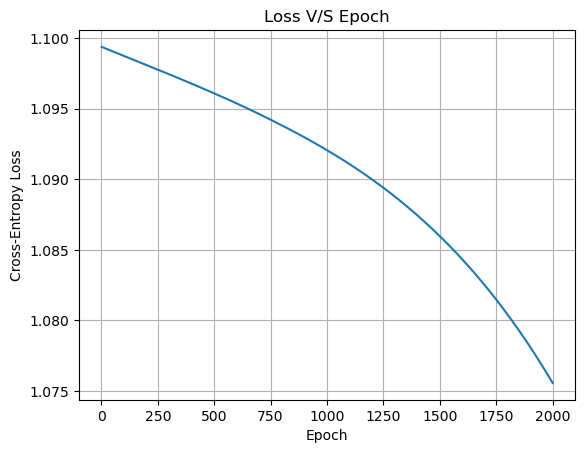

In [20]:
plt.plot(range(1, epochs+1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Loss V/S Epoch")
plt.grid(True)
plt.show()

In [22]:
Z1 = np.dot(X_test, W1) + b1
A1 = relu(Z1)
Z2 = np.dot(A1, W2) + b2
prob = softmax(Z2)

y_pred = np.argmax(prob, axis=1)

print("Test Accuracy :", accuracy_score(y_test, y_pred)*100, "%")

Test Accuracy : 73.33333333333333 %


In [23]:
cr = classification_report(y_test, y_pred)
print("Classification Report :\n", cr)

Classification Report :
               precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      0.20      0.33        10
           2       0.59      1.00      0.74        10

    accuracy                           0.73        30
   macro avg       0.83      0.73      0.68        30
weighted avg       0.83      0.73      0.68        30

